### ZADATAK
Fajl Amazon_Reviews_for_class.csv sadrzi podatke o komentarima proizvoda koji se prodaju preko Amazon platforme. Koristeci varijable koje se odnose na sadrzaj komentara (Summary i Text), izvrsiti klasterizaciju komentara primenom aglomerativenog hijerarhijskog klasterovanja.

Za vektorsku reprezentaciju komentara koristiti ili vektore reci raspolozive u okviru spacymodela ili vektorske reprezentacije teksta koje generise neki od sentence transformers (SBERT) modela.

In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc

import matplotlib.pyplot as plt
from pypalettes import load_cmap

from pathlib import Path
from dotenv import load_dotenv
import os

In [2]:
RAND_STATE = 1

PRETRAINED_LM = "all-MiniLM-L12-v2"

In [3]:
from sentence_transformers import SentenceTransformer

C:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### UCITAVANJE I PREGLED PODATAKA

In [4]:
data = pd.read_csv(Path.cwd() / 'data' / 'Amazon_Reviews_for_class.csv')

data.head()

,ProductId,UserId,Score,Summary,Text
0,B0007A0AQM,A3LTMOK0JARRER,5,Natural goodness!,I love that these are not only a very tasty tr...
1,B007TJGZ54,A3DUXSSTG7Y87M,5,It's Some Good Joe,It's some good Joe. If you are looking for a m...
2,B006N3IG4K,AP03SDCDB6RBD,3,Wolfgang Puck Sorrento K-cups,We have tried just about every k-cup of regula...
3,B00474VPY0,AP6VFQES99HAY,5,Best coffee,This was sold out at Cafe Express site. Thril...
4,B00286K7IO,A2UQISU6GQ1GF9,5,DELICIOUS AND GREAT SINGLE SERVINGS!!!,We used to buy this product at our local super...


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ProductId  4000 non-null   object
 1   UserId     4000 non-null   object
 2   Score      4000 non-null   int64 
 3   Summary    4000 non-null   object
 4   Text       4000 non-null   object
dtypes: int64(1), object(4)
memory usage: 156.4+ KB


In [6]:
data.duplicated().sum()

np.int64(0)

Za klasterizaciju koristimo kolone `Summary` i `Text`. Spojicemo ove dve kolone u jednu zajednicku, kako bismo dobili kompletniji tekst svake rezencije, i tako dobijeni tekst koristimo u daljoj obradi i klasterizaciji.

In [7]:
data['Content'] = data.apply(lambda x: f"{x.Summary}. {x.Text}", axis=1)

data[['Summary', 'Text', 'Content']].head()

,Summary,Text,Content
0,Natural goodness!,I love that these are not only a very tasty tr...,Natural goodness!. I love that these are not o...
1,It's Some Good Joe,It's some good Joe. If you are looking for a m...,It's Some Good Joe. It's some good Joe. If you...
2,Wolfgang Puck Sorrento K-cups,We have tried just about every k-cup of regula...,Wolfgang Puck Sorrento K-cups. We have tried j...
3,Best coffee,This was sold out at Cafe Express site. Thril...,Best coffee. This was sold out at Cafe Express...
4,DELICIOUS AND GREAT SINGLE SERVINGS!!!,We used to buy this product at our local super...,DELICIOUS AND GREAT SINGLE SERVINGS!!!. We use...


Pre embeddings-a provericemo duzinu svake rezencije jer izabrani model prima 256 tokena tj. `do 200 reci`. U slucaju da je rezencije sadrze preko 200 reci, uzecemo samo one koje ispunjavaju uslov.

In [8]:
data['WordCount'] = data.Content.apply(lambda x: len(x.split()))
data.WordCount.describe()

count    4000.00000
mean       84.93125
std        86.27230
min        14.00000
25%        37.00000
50%        60.00000
75%       102.00000
max      1466.00000
Name: WordCount, dtype: float64

In [9]:
data_sub = data.loc[data.WordCount <= 200].copy()

# uradicemo reset indeksa
data_sub.reset_index(drop=True, inplace=True)

data_sub.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3741 entries, 0 to 3740
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ProductId  3741 non-null   object
 1   UserId     3741 non-null   object
 2   Score      3741 non-null   int64 
 3   Summary    3741 non-null   object
 4   Text       3741 non-null   object
 5   Content    3741 non-null   object
 6   WordCount  3741 non-null   int64 
dtypes: int64(2), object(5)
memory usage: 204.7+ KB


In [10]:
data_sub.WordCount.describe()

count    3741.000000
mean       68.685378
std        42.064283
min        14.000000
25%        36.000000
50%        56.000000
75%        91.000000
max       200.000000
Name: WordCount, dtype: float64

#### UCITAVANJE MODELA

In [11]:
load_dotenv()

if os.getenv('HF_TOKEN'):
    print('USPESNO ucitan token')
else:
    print('GRESKA')

USPESNO ucitan token


In [12]:
model = SentenceTransformer(PRETRAINED_LM)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1801.19it/s]


#### EMBEDDINGS

In [13]:
reviews_embeddings = model.encode(data_sub.Content.to_numpy())

reviews_embeddings.shape

(3741, 384)

#### KOSINUSNA SLICNOST

In [14]:
reviews_simmilarities = cosine_similarity(reviews_embeddings, reviews_embeddings)

reviews_simmilarities.shape

(3741, 3741)

#### KOSINUSNA UDALJENOST

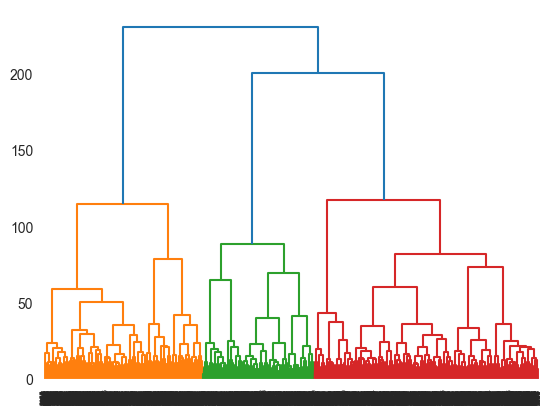

In [15]:
reviews_dist = 1 - reviews_simmilarities

ward_linkage = shc.linkage(reviews_dist, method='ward')

plt.figure()
shc.dendrogram(ward_linkage)
plt.show()

#### ODREDJIVANJE OPTIMALNOG BROJA KLASTERA

Na osnovu dendograma moze se zakljuciti da je optimalan broj klastera izmedju `3 i 5`

Koristicemo i druge metrike za ovu odluku - `Silhouette score`

In [16]:
sil_scores = []

for k in range(3, 6):
    # klasterizacija za svaki broj klastera
    agg_clust = shc.fcluster(ward_linkage, t=k, criterion='maxclust')
    # uklanjanje negativnih kosinusnih udaljenosti
    reviews_dist_clipped = np.clip(reviews_dist, a_min=0.0, a_max=None)
    # racunanje prosecnog silhouette score-a
    score = silhouette_score(reviews_dist_clipped, agg_clust, metric='precomputed')

    sil_scores.append(score)

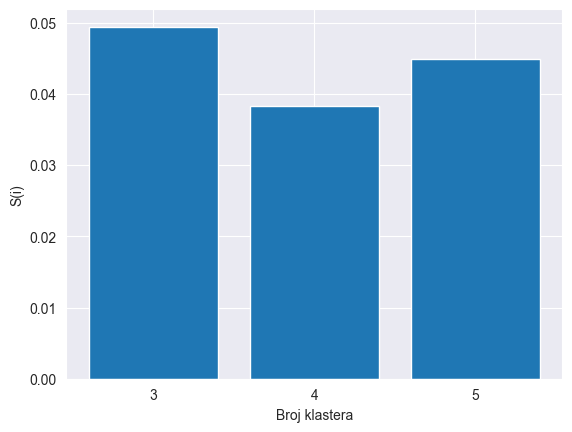

In [17]:
plt.bar(range(3, 6), sil_scores)
plt.xticks(range(3, 6))
plt.xlabel('Broj klastera')
plt.ylabel('S(i)')
plt.show()

Silhouette score je u proseku veoma mali sto ukazuje na to da klasteri nisu dovoljno razdvojeni.

Napravicemo klasterizaciju sa 3 klastera, s obzirom da je tu najveci silhouette score.

In [18]:
agg_clust_opt = shc.fcluster(ward_linkage, t=3, criterion='maxclust')

data_sub['Cluster'] = agg_clust_opt

data_sub.Cluster.value_counts()

Cluster
3    1693
1    1209
2     839
Name: count, dtype: int64

Postoji neuravnotezenost po klasterima. Mada, po dendogramu ona bi postojala za bilo koji broj klastera.

#### ODREDJIVANJE KLJUCNIH RECI PO KLASTERIMA

In [19]:
# napravicemo svoju f-ju za preprocesiranje teksta
import spacy

nlp_pipe = spacy.load('en_core_web_sm', disable=['par', 'ner'])


def spacy_preprocessing(doc):
    tokens = nlp_pipe(doc)

    tokens = [token for token in tokens
              if ((not token.is_space) and (not token.like_num) and (not token.like_url) and (not token.is_stop) and (
            not token.is_punct))]

    tokens = [token for token in tokens
              if token.pos_ in ['NOUN']]

    words = [token.lemma_ for token in tokens]

    return words

In [20]:
def get_top_ngrams(cluster_id, top_n=10, words_to_remove=None):
    tfidf_vectorizer = TfidfVectorizer(tokenizer=spacy_preprocessing, token_pattern=None, ngram_range=(1, 2))

    # izvlacenje svih rezencija za izabrani klaster
    cluster_reviews = data_sub.loc[data_sub.Cluster == cluster_id].Content
    # racunanje tf_idf vrednosti za svaku rezenciju
    cluster_tfidf = tfidf_vectorizer.fit_transform(cluster_reviews)
    # vracanje svih ngrama koji su se pojavili
    candidate_keywords = tfidf_vectorizer.get_feature_names_out()

    # racunamo prosecnu tfidf vrednost svakog ngrama kroz sve rezencije
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=0)).flatten()

    # kreiramo uredjeni par (ngram, tf_idf) i sortiramo po score-u
    sorted_candidates = sorted([(keyword, tfidf_score) for keyword, tfidf_score in zip(candidate_keywords, mean_tfidf)],
                               key=lambda x: x[1], reverse=True)

    if words_to_remove:
        sorted_candidates = [(keyword, tfidf) for keyword, tfidf in sorted_candidates if keyword not in words_to_remove]

    return sorted_candidates[:top_n]

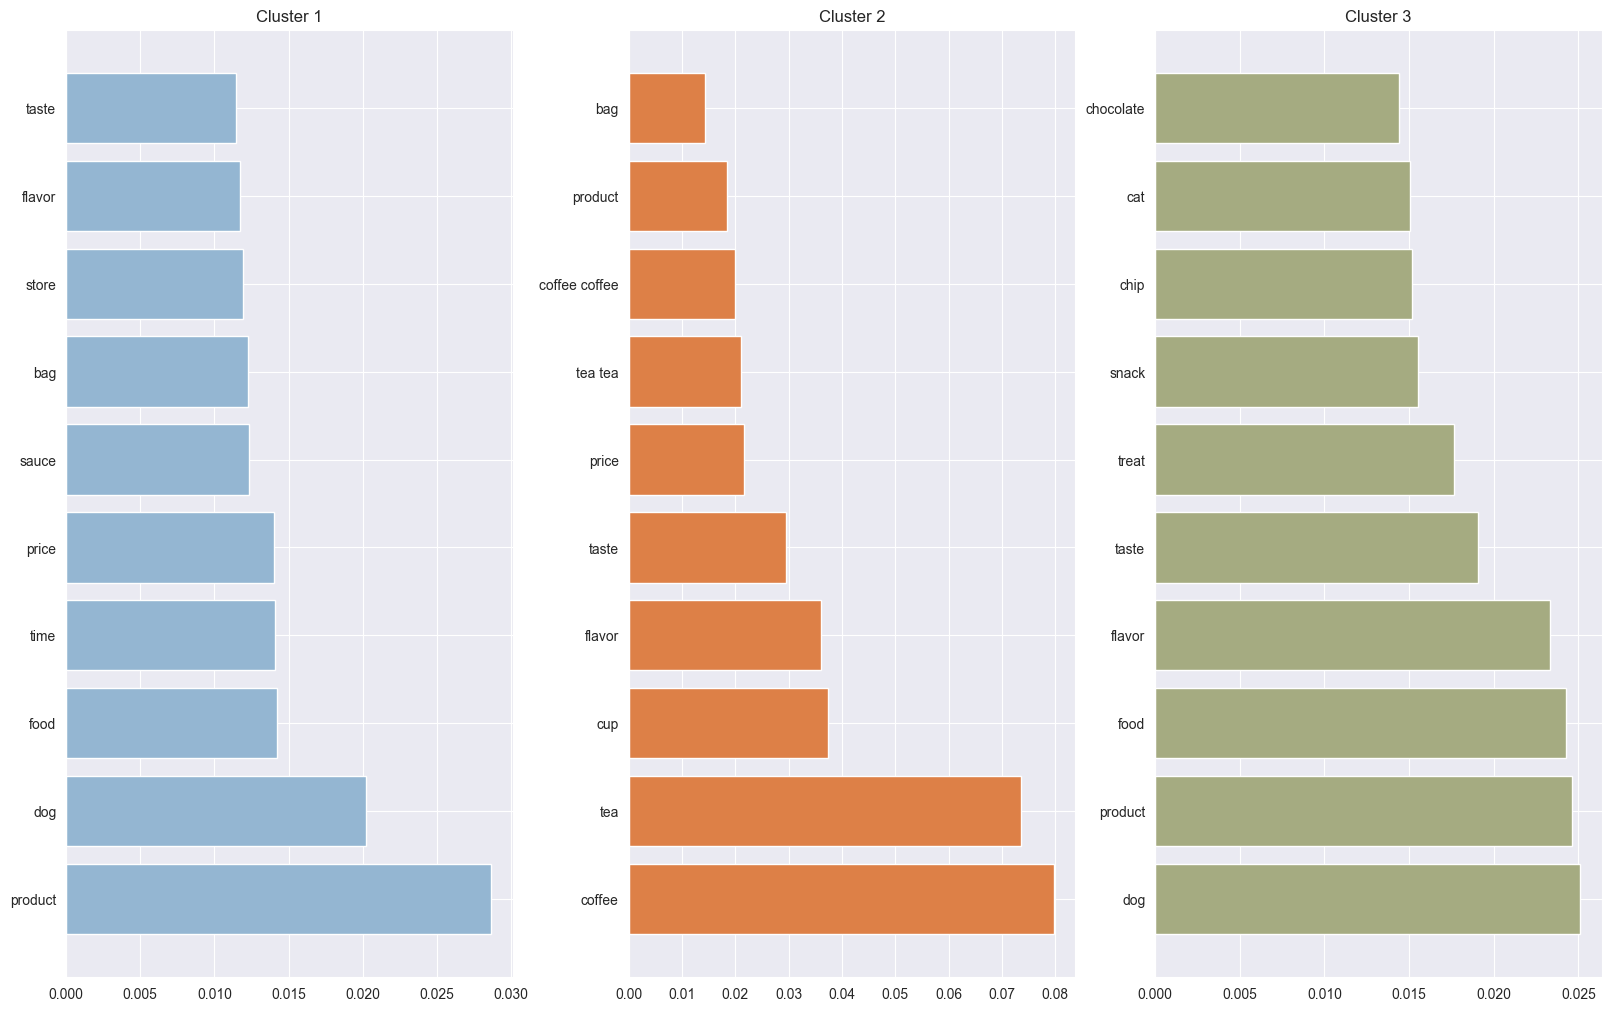

In [22]:
fix, ax_grid = plt.subplots(nrows=1, ncols=3, figsize=(16, 10), constrained_layout=True)

axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data_sub.Cluster.nunique()
for i in range(n_clust):
    data = get_top_ngrams(i + 1)
    scores = [s for kw, s in data]
    keywords = [kw for kw, s in data]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i + 1}")

plt.show()

Na osnovu 10 najznacajnijih reci za svaki klaster (ostavili smo samo imenice), mozemo otprilike da pretpostavimo o kojim proizvodima je rec:

Klaster 1: ne moze se sa sigurnoscu utvrditi, ali nakon uzorka rezencija mozemo reci da je rec o raznovrsnim proizvodima - hrana i igracke (za ljude i ljubimce), namirnice za kuvanje...

Klaster 2: kafa i caj

Klaster 3: hrana za kucne ljubimce

In [25]:
data_sub.loc[data_sub.Cluster == 1].Content.sample(20)

2521    THANK YOU. The stores that use to stock this i...
3009    Everything you would expect. This is exactly w...
930     The perfect summer sausage. I finally found th...
1674    Price Skyrocketed. I used to get this on the A...
1556    Pasta for Peace. Annie's Peace Pasta is a deli...
3160    over 50 fun. What fun to open up the box of re...
2155    Yum. Do I really need say more? YUMMM! Arrived...
443     bad beef. I'm normally a fan of jack links but...
1872    The marshmallows are tiny pellets that are pac...
2208    Bad batch. Our ridgeback had been on Prairie f...
1265    Tastes good, high yield, but salt and kernels ...
1668    Keeps my cats happy and healthy. I don't know ...
3447    I don't even have a dog :). I used these for p...
912     It's Hummus Time!. Anytime is hummus time, at ...
476     Price is waaaaaay off. 22.40?? THIS WAS 11.49!...
873     How much for shipping???. This food is great. ...
1038    The best way to start your day. I've had more ...
1423    Maggi 